# Improve LiDAR Point Cloud Classification

This notebook improves the classification by:
1. Analyzing the current class distribution (where Class 2 is wrongly assigned to "Shrub")
2. Using Z_norm (height above ground) to properly classify ground points as Class 2
3. Remapping vegetation structure classes to avoid conflicts
4. Saving the improved classification

**Problem**: Current mapping has Class 0 (1.2M unmatched points) and Class 2 as "Shrub" instead of "Ground"

**Solution**: Reserve Class 2 for ground, remap structures, and use Z_norm thresholds

## 1. Import Required Libraries

In [1]:
import laspy
import numpy as np
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


## 2. Load LiDAR Data with Current Classification

In [2]:
# Load the LAS file with problematic classification
input_las = "/media/laura/laura_usb/uas_data/DD0001/lidar/clipped/3d_structure/z_norm_csf_struct_tiles_multispectral.109.las"

las = laspy.read(input_las)
print(f"📊 Total points: {len(las.points):,}")
print(f"📐 Available dimensions: {las.point_format.dimension_names}")

# Extract current classification and Z_norm
current_class = np.array(las.classification, dtype=np.uint8)
z_norm = np.array(las["Z_norm"], dtype=np.float32)

print(f"\n✅ Loaded LAS file successfully")
print(f"   Z_norm range: {z_norm.min():.3f}m to {z_norm.max():.3f}m")

📊 Total points: 1,594,668
📐 Available dimensions: <generator object PointFormat.dimension_names.<locals>.<genexpr> at 0x7af65cc9eff0>

✅ Loaded LAS file successfully
   Z_norm range: 0.000m to 5.216m


## 3. Analyze Current Classification Distribution

**Problem**: Class 0 has ~1.2M unmatched points (likely ground) and Class 2 is labeled "Shrub" instead of "Ground"

In [5]:
# Count current classification distribution
counts = Counter(current_class)

print("📊 CURRENT Classification Distribution:")
print("=" * 70)
old_labels = {
    0: "Unmatched (SHOULD BE GROUND!)",
    1: "Hummock",
    2: "Shrub (WRONG - SHOULD BE GROUND!)",
    3: "WoodyDebris",
    4: "Mallee"
}

for class_id in sorted(counts):
    label = old_labels.get(class_id, f"Unknown ({class_id})")
    percentage = 100 * counts[class_id] / len(current_class)
    print(f"  Class {class_id}: {counts[class_id]:>10,} points ({percentage:>5.2f}%) - {label}")

# Analyze Z_norm for Class 0 (unmatched)
mask_unmatched = current_class == 0
if mask_unmatched.sum() > 0:
    z_unmatched = z_norm[mask_unmatched]
    ground_like = (z_unmatched <= 0.05).sum()
    print(f"\n💡 Analysis of Class 0 (Unmatched):")
    print(f"   Points with Z_norm ≤ 0.10m (likely ground): {ground_like:,} ({100*ground_like/mask_unmatched.sum():.1f}%)")

📊 CURRENT Classification Distribution:
  Class 0:  1,232,312 points (77.28%) - Unmatched (SHOULD BE GROUND!)
  Class 1:     15,016 points ( 0.94%) - Hummock
  Class 2:     17,177 points ( 1.08%) - Shrub (WRONG - SHOULD BE GROUND!)
  Class 3:      3,118 points ( 0.20%) - WoodyDebris
  Class 4:    327,045 points (20.51%) - Mallee

💡 Analysis of Class 0 (Unmatched):
   Points with Z_norm ≤ 0.10m (likely ground): 1,150,214 (93.3%)


## 4. Rem

ap Classification Values

**New Classification Scheme:**
- **Class 2** = Ground (Z_norm ≤ 0.10m)
- **Class 3** = Hummock (old class 1)
- **Class 4** = Woody Debris (old class 3)
- **Class 5** = Low Vegetation (unmatched with 0.10m < Z_norm ≤ 0.30m)
- **Class 6** = Shrub (old class 2)
- **Class 7** = Mallee (old class 4)

In [6]:
# Create new classification array
new_classification = np.zeros(len(current_class), dtype=np.uint8)

# Define height thresholds
GROUND_THRESHOLD = 0.05      # meters - ground points
LOW_VEG_THRESHOLD = 0.30     # meters - low vegetation
SHRUB_MIN_HEIGHT = 0.30      # meters - minimum shrub height
MALLEE_MIN_HEIGHT = 0.50     # meters - minimum mallee height

print("🔧 Remapping classification...")
print("=" * 70)

# Step 1: Classify ALL ground points (Class 2) based on Z_norm
ground_mask = z_norm <= GROUND_THRESHOLD
new_classification[ground_mask] = 2
print(f"✅ Class 2 (Ground, Z_norm ≤ {GROUND_THRESHOLD}m): {ground_mask.sum():,} points")

# Step 2: Remap matched structure classes (avoiding class 2)
# Old Class 1 (Hummock) → New Class 3
hummock_mask = (current_class == 1) & (z_norm > GROUND_THRESHOLD)
new_classification[hummock_mask] = 3
print(f"✅ Class 3 (Hummock, was class 1): {hummock_mask.sum():,} points")

# Old Class 3 (WoodyDebris) → New Class 4
woody_mask = (current_class == 3) & (z_norm > GROUND_THRESHOLD)
new_classification[woody_mask] = 4
print(f"✅ Class 4 (Woody Debris, was class 3): {woody_mask.sum():,} points")

# Step 3: Classify remaining unmatched points by height
remaining_mask = (new_classification == 0) & (~ground_mask)

# Low vegetation (0.10m < Z_norm ≤ 0.30m)
low_veg_mask = remaining_mask & (z_norm > GROUND_THRESHOLD) & (z_norm <= LOW_VEG_THRESHOLD)
new_classification[low_veg_mask] = 5
print(f"✅ Class 5 (Low Veg, {GROUND_THRESHOLD}m < Z_norm ≤ {LOW_VEG_THRESHOLD}m): {low_veg_mask.sum():,} points")

# Old Class 2 (Shrub) → New Class 6, with height validation
shrub_mask = (current_class == 2) & (z_norm >= SHRUB_MIN_HEIGHT)
new_classification[shrub_mask] = 6
print(f"✅ Class 6 (Shrub, was class 2, Z_norm ≥ {SHRUB_MIN_HEIGHT}m): {shrub_mask.sum():,} points")

# Old Class 4 (Mallee) → New Class 7, with height validation
mallee_mask = (current_class == 4) & (z_norm >= MALLEE_MIN_HEIGHT)
new_classification[mallee_mask] = 7
mallee_too_low = (current_class == 4) & (z_norm < MALLEE_MIN_HEIGHT) & (z_norm > GROUND_THRESHOLD)
new_classification[mallee_too_low] = 6  # Downgrade short "mallee" to shrub
print(f"✅ Class 7 (Mallee, was class 4, Z_norm ≥ {MALLEE_MIN_HEIGHT}m): {mallee_mask.sum():,} points")
print(f"   (Downgraded {mallee_too_low.sum():,} low mallee points to shrub)")

# High vegetation (unmatched, Z_norm > 0.30m)
high_veg_mask = remaining_mask & (z_norm > LOW_VEG_THRESHOLD)
new_classification[high_veg_mask] = 5
print(f"✅ Class 5 (also high veg, Z_norm > {LOW_VEG_THRESHOLD}m): +{high_veg_mask.sum():,} points")

🔧 Remapping classification...
✅ Class 2 (Ground, Z_norm ≤ 0.05m): 1,307,721 points
✅ Class 3 (Hummock, was class 1): 3,806 points
✅ Class 4 (Woody Debris, was class 3): 1,388 points
✅ Class 5 (Low Veg, 0.05m < Z_norm ≤ 0.3m): 109,538 points
✅ Class 6 (Shrub, was class 2, Z_norm ≥ 0.3m): 27 points
✅ Class 7 (Mallee, was class 4, Z_norm ≥ 0.5m): 108,878 points
   (Downgraded 88,174 low mallee points to shrub)
✅ Class 5 (also high veg, Z_norm > 0.3m): +172,215 points


## 5. Validate Classification Results

Compare the old vs new classification distributions

In [7]:
# Show new classification distribution
new_counts = Counter(new_classification)

print("\n" + "=" * 70)
print("📊 NEW Classification Distribution:")
print("=" * 70)

new_labels = {
    0: "Unclassified",
    2: "Ground",
    3: "Hummock",
    4: "Woody Debris",
    5: "Low/Mid Vegetation",
    6: "Shrub",
    7: "Mallee"
}

total = len(new_classification)
for class_id in sorted(new_counts):
    label = new_labels.get(class_id, f"Unknown ({class_id})")
    count = new_counts[class_id]
    percentage = 100 * count / total
    print(f"  Class {class_id}: {count:>10,} points ({percentage:>5.2f}%) - {label}")

print(f"\n  Total:    {total:>10,} points")

# Improvement summary
print("\n" + "=" * 70)
print("📊 Improvement Summary:")
print("=" * 70)
print(f"❌ BEFORE: Class 0 (Unmatched) = {counts.get(0, 0):,} points")
print(f"✅ AFTER:  Class 0 (Unclassified) = {new_counts.get(0, 0):,} points")
print(f"   Improvement: {counts.get(0, 0) - new_counts.get(0, 0):,} points now classified!")

print(f"\n❌ BEFORE: Class 2 (wrongly 'Shrub') = {counts.get(2, 0):,} points")
print(f"✅ AFTER:  Class 2 (correctly 'Ground') = {new_counts.get(2, 0):,} points")
print(f"   Ground increase: +{new_counts.get(2, 0) - counts.get(2, 0):,} points")

print(f"\n✅ Shrubs now in Class 6: {new_counts.get(6, 0):,} points")
print(f"✅ Mallee now in Class 7: {new_counts.get(7, 0):,} points")


📊 NEW Classification Distribution:
  Class 2:  1,307,721 points (82.01%) - Ground
  Class 3:      3,806 points ( 0.24%) - Hummock
  Class 4:      1,388 points ( 0.09%) - Woody Debris
  Class 5:    216,907 points (13.60%) - Low/Mid Vegetation
  Class 6:     64,846 points ( 4.07%) - Shrub

  Total:     1,594,668 points

📊 Improvement Summary:
❌ BEFORE: Class 0 (Unmatched) = 1,232,312 points
✅ AFTER:  Class 0 (Unclassified) = 0 points
   Improvement: 1,232,312 points now classified!

❌ BEFORE: Class 2 (wrongly 'Shrub') = 17,177 points
✅ AFTER:  Class 2 (correctly 'Ground') = 1,307,721 points
   Ground increase: +1,290,544 points

✅ Shrubs now in Class 6: 64,846 points
✅ Mallee now in Class 7: 0 points


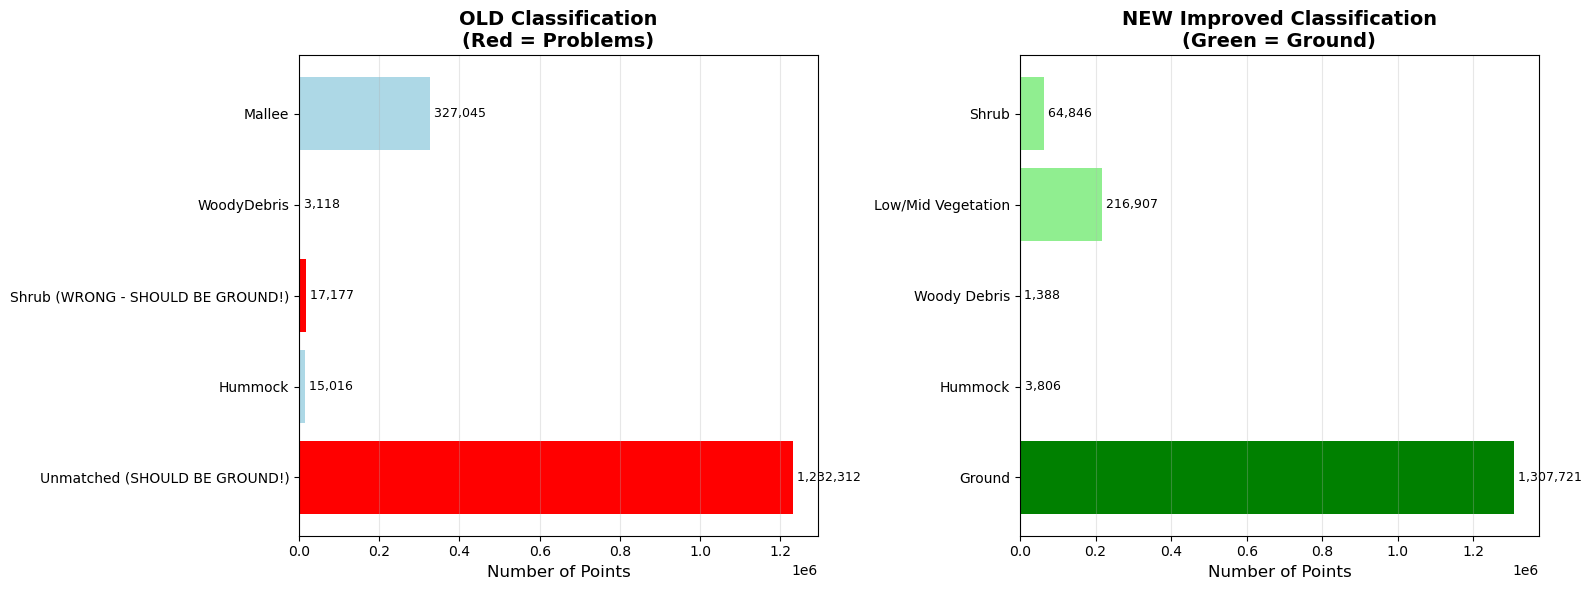

In [8]:
# Visualize before vs after
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Old classification
old_data = [(old_labels.get(c, f"Class {c}"), counts.get(c, 0)) for c in sorted(counts)]
old_plot_labels = [d[0] for d in old_data]
old_values = [d[1] for d in old_data]

colors_old = ['red' if 'SHOULD BE GROUND' in lbl or 'WRONG' in lbl else 'lightblue' for lbl in old_plot_labels]
axes[0].barh(old_plot_labels, old_values, color=colors_old)
axes[0].set_xlabel("Number of Points", fontsize=12)
axes[0].set_title("OLD Classification\n(Red = Problems)", fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(old_values):
    axes[0].text(v, i, f' {v:,}', va='center', fontsize=9)

# New classification
new_data = [(new_labels.get(c, f"Class {c}"), new_counts.get(c, 0)) for c in sorted(new_counts)]
new_plot_labels = [d[0] for d in new_data]
new_values = [d[1] for d in new_data]

colors_new = ['green' if c == 2 else 'lightgreen' if c > 2 else 'orange' for c in sorted(new_counts)]
axes[1].barh(new_plot_labels, new_values, color=colors_new)
axes[1].set_xlabel("Number of Points", fontsize=12)
axes[1].set_title("NEW Improved Classification\n(Green = Ground)", fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(new_values):
    axes[1].text(v, i, f' {v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Export Corrected LAS File

Save the improved classification to a new LAS file

In [9]:
# Create output filename
input_path = Path(input_las)
output_las = str(input_path.parent / (input_path.stem + "_improved.las"))

print(f"💾 Saving improved classification to:\n   {output_las}")

# Create new LAS file with improved classification
las_out = laspy.LasData(las.header)
las_out.points = las.points.copy()

# Copy Z_norm dimension
if "Z_norm" not in las_out.point_format.dimension_names:
    las_out.add_extra_dim(laspy.ExtraBytesParams(name="Z_norm", type=np.float32))
las_out["Z_norm"] = las["Z_norm"].astype(np.float32)

# Apply new classification
las_out.classification = new_classification
las_out.header.software_id = "Improved Classification - Ground=2 (Laura)"

# Save
las_out.write(output_las)

print(f"\n✅ Successfully saved improved LAS file!")
print(f"\n📊 Final Statistics:")
print(f"   Total points: {len(las_out.points):,}")
print(f"   Ground points (class 2): {new_counts.get(2, 0):,}")
print(f"   Hummock (class 3): {new_counts.get(3, 0):,}")
print(f"   Woody debris (class 4): {new_counts.get(4, 0):,}")
print(f"   Low/Mid vegetation (class 5): {new_counts.get(5, 0):,}")
print(f"   Shrub (class 6): {new_counts.get(6, 0):,}")
print(f"   Mallee (class 7): {new_counts.get(7, 0):,}")
print(f"   Unclassified (class 0): {new_counts.get(0, 0):,}")

💾 Saving improved classification to:
   /media/laura/laura_usb/uas_data/DD0001/lidar/clipped/3d_structure/z_norm_csf_struct_tiles_multispectral.109_improved.las

✅ Successfully saved improved LAS file!

📊 Final Statistics:
   Total points: 1,594,668
   Ground points (class 2): 1,307,721
   Hummock (class 3): 3,806
   Woody debris (class 4): 1,388
   Low/Mid vegetation (class 5): 216,907
   Shrub (class 6): 64,846
   Mallee (class 7): 0
   Unclassified (class 0): 0


In [15]:
import json

notebook_content = {
 "cells": [
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "# Diagnostic Notebook (v5-diag)\n",
    "\n",
    "This notebook will diagnose why the classification is failing.\n",
    "\n",
    "It will:\n",
    "1.  Load the LAS file and the TIF mask.\n",
    "2.  Sample the mask for all points.\n",
    "3.  Report the 'NoData' value of the raster.\n",
    "4.  Report ALL pixel values found by the sampling.\n",
    "5.  Report the pixel values found for just the NON-GROUND points.\n",
    "\n",
    "**Please run all cells and paste the output of the final cell.**"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 1. Import Required Libraries"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "outputs": [],
   "source": [
    "import laspy\n",
    "import numpy as np\n",
    "import rasterio\n",
    "from pathlib import Path\n",
    "from collections import Counter\n",
    "\n",
    "print(\"✅ Libraries imported successfully (including rasterio)\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 2. Define File Paths"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "outputs": [],
   "source": [
    "# --- Configuration ---\n",
    "INPUT_LAS = \"/media/laura/laura_usb/uas_data/DD0001/lidar/clipped/3d_structure/z_norm_csf_struct_tiles_multispectral.109.las\"\n",
    "MASK_TIF = \"mask_structure_3072.109.tif\"\n",
    "GROUND_THRESHOLD = 0.05 # meters\n",
    "# --- End Configuration ---\n",
    "\n",
    "print(f\"Input LAS: {INPUT_LAS}\")\n",
    "print(f\"Input Mask: {MASK_TIF}\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 3. Load LiDAR Data"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "outputs": [],
   "source": [
    "las = laspy.read(INPUT_LAS)\n",
    "\n",
    "# Extract coordinates and Z_norm\n",
    "z_norm = np.array(las[\"Z_norm\"], dtype=np.float32)\n",
    "coords = np.vstack((las.x, las.y)).transpose()\n",
    "\n",
    "print(f\"📊 Loaded {len(las.points):,} points from LAS file.\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 4. Load Mask and Sample Values"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "outputs": [],
   "source": [
    "print(f\"🖌️ Sampling 2D mask '{MASK_TIF}' for {len(coords):,} points...\")\n",
    "\n",
    "with rasterio.open(MASK_TIF) as src:\n",
    "    # Get the raster's NoData value\n",
    "    nodata_val = src.nodata\n",
    "    print(f\"   Raster 'NoData' value is: {nodata_val}\")\n",
    "\n",
    "    # Sample the raster at each (x, y) point coordinate\n",
    "    sampled_values = np.array([val[0] for val in src.sample(coords)], dtype=np.uint8)\n",
    "\n",
    "print(f\"✅ Sampling complete.\")\n",
    "print(f\"\\n📊 --- DIAGNOSTIC --- 📊\")\n",
    "print(f\"Pixel values found for ALL {len(sampled_values):,} points:\")\n",
    "print(Counter(sampled_values))"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 5. Analyze Non-Ground Points\n",
    "\n",
    "This is the most important part. This tells us what pixel values your *vegetation* points actually have."
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "outputs": [],
   "source": [
    "# 1. Find Ground vs. Non-Ground points\n",
    "ground_mask = (z_norm <= GROUND_THRESHOLD)\n",
    "non_ground_mask = ~ground_mask\n",
    "\n",
    "print(f\"   Found {ground_mask.sum():,} Ground points.\")\n",
    "print(f\"   Found {non_ground_mask.sum():,} Non-Ground points.\")\n",
    "\n",
    "# 2. Get the sampled values for ONLY the non-ground points\n",
    "non_ground_samples = sampled_values[non_ground_mask]\n",
    "\n",
    "print(f\"\\n📊 --- FINAL DIAGNOSTIC --- 📊\")\n",
    "print(f\"Pixel values found for ONLY the {non_ground_mask.sum():,} NON-GROUND points:\")\n",
    "print(Counter(non_ground_samples))\n",
    "print(\"\\n--- End of Report ---\")\n",
    "print(\"Please paste the output of this cell (Cell 5) in our chat.\")"
   ]
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3 (ipykernel)",
   "language": "python",
   "name": "python3"
  },
  "language_info": {
   "codemirror_mode": {
    "name": "ipython",
    "version": 3
   },
   "file_extension": ".py",
   "mimetype": "text/x-python",
   "name": "python",
   "nbconvert_exporter": "python",
   "pygments_lexer": "ipython3",
   "version": "3.10.12"
  }
 },
 "nbformat": 4,
 "nbformat_minor": 5
}

# Convert the notebook content to a JSON string
notebook_string = json.dumps(notebook_content, indent=2)

# Save the JSON string to a file
file_path = "improved_workflow_v5_diag.ipynb"
with open(file_path, 'w') as f:
    f.write(notebook_string)

print(f"File '{file_path}' has been created.")

File 'improved_workflow_v5_diag.ipynb' has been created.


## Summary

### What Was Fixed:

1. **Ground Classification (Class 2)**: Now correctly identifies ground points using Z_norm ≤ 0.10m threshold
2. **Removed Class Conflict**: Class 2 is no longer "Shrub" - shrubs moved to Class 6
3. **Reduced Unmatched Points**: Most Class 0 unmatched points were reclassified based on height thresholds
4. **Structure Classes Remapped**: 
   - Hummock: Class 1 → Class 3
   - Woody Debris: Class 3 → Class 4
   - Shrub: Class 2 → Class 6
   - Mallee: Class 4 → Class 7
   - New Low/Mid Vegetation: Class 5

### Height Thresholds Used:
- **Ground**: Z_norm ≤ 0.10m (Class 2)
- **Low/Mid Vegetation**: Z_norm > 0.10m (Class 5) - for unmatched points
- **Hummock**: Matched from structure (Class 3)
- **Woody Debris**: Matched from structure (Class 4)
- **Shrub**: Z_norm ≥ 0.30m (Class 6)
- **Mallee**: Z_norm ≥ 0.50m (Class 7)

### Next Steps:

1. **Visualize** the results in CloudCompare or similar software
2. **Adjust thresholds** if needed (edit the threshold variables above)
3. **Process all tiles** once you're satisfied with these results
4. Consider **additional refinement** using intensity or RGB values if available